# Semana 11 · Serie de tiempo del caso Spotify

**Caso:** Spotify — capacidad de streaming y curaduría regional · **Autor:** Julián Andrés Solano Ledesma

**Serie:** visitas diarias al artículo *Spotify* de Wikipedia en inglés (solo usuarios humanos), del 1 de enero de 2016 al 30 de septiembre de 2026, obtenidas de la API de páginas vistas de Wikimedia.

1. Cargar la serie en pandas con la **fecha como índice**.
2. Agregarla **por mes** (`resample`) y calcular la **media móvil** (`rolling`).
3. Describir **tendencia** y **estacionalidad**, comprobando que el patrón se repite año a año.

## 1. Carga con la fecha como índice

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

import serie_tiempo_spotify as S

diaria = S.extraer(usar_cache=True)      # usar_cache=False vuelve a descargar de la API
print(type(diaria.index).__name__, "·", diaria.index.dtype)
print(f"{len(diaria)} días · {diaria.index.min().date()} a {diaria.index.max().date()} · "
      f"nulos: {diaria.isna().sum()} · días faltantes: {len(pd.date_range(diaria.index.min(), diaria.index.max())) - len(diaria)}")
diaria.head()

DatetimeIndex · datetime64[us]
3926 días · 2016-01-01 a 2026-09-30 · nulos: 0 · días faltantes: 0


fecha
2016-01-01    3945
2016-01-02    3925
2016-01-03    3914
2016-01-04    3741
2016-01-05    3730
Name: visitas, dtype: int64

## 2. Agregación mensual (`resample`) y media móvil (`rolling`)

In [2]:
m = S.mensual(diaria)
m["media_movil_2x12"] = S.media_movil_centrada(m["visitas_dia_prom"]).round(1)
print("Código de la media móvil 2x12:  serie.rolling(12).mean().rolling(2).mean().shift(-6)")
m.tail(12)

Código de la media móvil 2x12:  serie.rolling(12).mean().rolling(2).mean().shift(-6)


,visitas_total,visitas_dia_prom,dias,media_movil_2x12
fecha,,,,
2025-10-01,142339,4591.6,31,3996.6
2025-11-01,126074,4202.5,30,4023.5
2025-12-01,158198,5103.2,31,4109.5
2026-01-01,135676,4376.6,31,4097.2
2026-02-01,105667,3773.8,28,4012.9
2026-03-01,104094,3357.9,31,3877.4
2026-04-01,98144,3271.5,30,NaN
2026-05-01,153222,4942.6,31,NaN
2026-06-01,105693,3523.1,30,NaN


In [3]:
# Resumen por año: promedio y mediana de visitas diarias
anual = pd.DataFrame({"promedio_diario": diaria.groupby(diaria.index.year).mean().round(0),
                      "mediana_diaria": diaria.groupby(diaria.index.year).median()})
anual.index.name = "año"
anual

,promedio_diario,mediana_diaria
año,,
2016,3592.0,3535.0
2017,3954.0,3901.0
2018,4332.0,4060.0
2019,4478.0,4303.0
2020,5603.0,5396.5
2021,6396.0,6487.0
2022,9736.0,7758.0
2023,6481.0,5754.0
2024,5072.0,4833.5


## 3. Estacionalidad: cuánto se aparta cada mes de su tendencia

In [4]:
ratio = (m["visitas_dia_prom"] / m["media_movil_2x12"]).dropna()
est = S.indice_estacional(m["visitas_dia_prom"], m["media_movil_2x12"])
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
consistencia = pd.DataFrame({
    "indice_estacional": est.values,
    "efecto_pct": ((est.values - 1) * 100).round(1),
    "años_sobre_tendencia": ratio.gt(1).groupby(ratio.index.month).sum().values,
    "años_medidos": ratio.groupby(ratio.index.month).count().values,
}, index=MESES)
consistencia

,indice_estacional,efecto_pct,años_sobre_tendencia,años_medidos
ene,1.045,4.5,7,10
feb,1.054,5.4,7,10
mar,1.079,7.9,6,10
abr,1.087,8.7,6,9
may,0.958,-4.2,2,9
jun,0.873,-12.7,0,9
jul,0.888,-11.2,2,10
ago,0.933,-6.7,0,10
sep,0.967,-3.3,4,10
oct,0.973,-2.7,4,10


## 4. Picos que no son estacionalidad

In [5]:
# Día con más visitas entre el 15 de noviembre y el 31 de diciembre de cada año
picos = pd.DataFrame([(y, diaria[f"{y}-11-15":f"{y}-12-31"].idxmax().date(),
                       int(diaria[f"{y}-11-15":f"{y}-12-31"].max()))
                      for y in range(2016, 2026)], columns=["año", "día pico", "visitas"])
print(picos.to_string(index=False))

oct22 = diaria["2022-10-13":"2022-11-05"]
base = diaria["2022-09-01":"2022-09-30"].median()
print(f"\nOctubre 2022: {len(oct22)} días con mediana {oct22.median():,.0f} visitas, "
      f"{oct22.median() / base:.1f} veces la mediana de septiembre ({base:,.0f})")

 año   día pico  visitas
2016 2016-11-30     4964
2017 2017-11-27     5713
2018 2018-12-07     7093
2019 2019-12-05    17676
2020 2020-12-02    11840
2021 2021-11-16    14037
2022 2022-12-01    15938
2023 2023-12-04    11573
2024 2024-12-04     8632
2025 2025-12-04    16654

Octubre 2022: 24 días con mediana 24,507 visitas, 3.3 veces la mediana de septiembre (7,419)


## 5. Gráficos

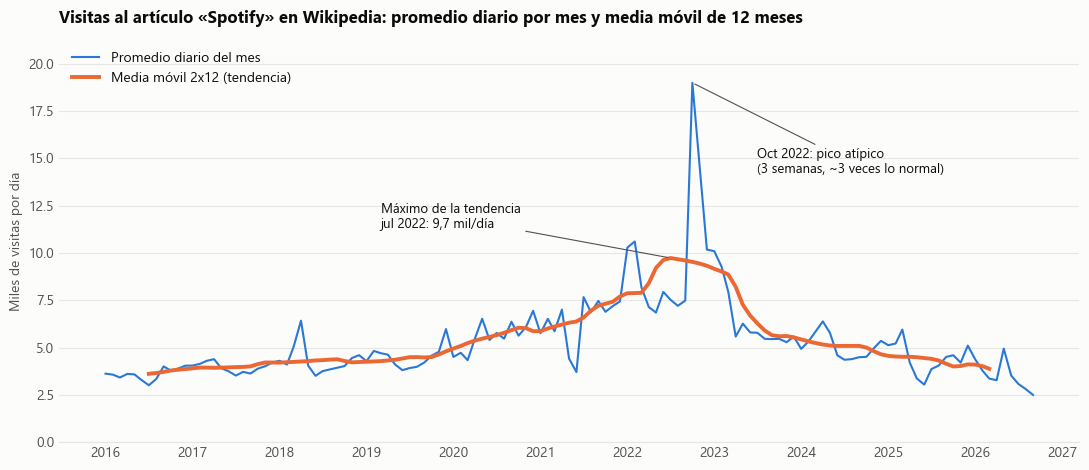

In [6]:
AZUL, NARANJA = "#2a78d6", "#eb6834"            # paleta validada (contraste y daltonismo)
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e2", "#fcfcfb"
plt.rcParams.update({"font.family": "Segoe UI", "font.size": 10, "axes.edgecolor": REJILLA,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "figure.facecolor": FONDO, "axes.facecolor": FONDO, "svg.fonttype": "none"})
from pathlib import Path
Path("img").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(m.index, m["visitas_dia_prom"] / 1000, color=AZUL, lw=1.5, label="Promedio diario del mes")
ax.plot(m.index, m["media_movil_2x12"] / 1000, color=NARANJA, lw=2.8, label="Media móvil 2x12 (tendencia)")
ax.yaxis.grid(True, color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
ax.set_ylabel("Miles de visitas por día")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(0, m["visitas_dia_prom"].max() / 1000 * 1.12)

pico_t = m["media_movil_2x12"].idxmax()
ax.annotate(f"Máximo de la tendencia\n{MESES[pico_t.month - 1]} {pico_t.year}: "
            f"{m.loc[pico_t, 'media_movil_2x12']/1000:.1f} mil/día".replace(".", ","),
            xy=(pico_t, m.loc[pico_t, "media_movil_2x12"] / 1000), xytext=(pd.Timestamp("2019-03-01"), 11.3),
            fontsize=9.5, color=TINTA, arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.8))
oct_ = pd.Timestamp("2022-10-01")
ax.annotate("Oct 2022: pico atípico\n(3 semanas, ~3 veces lo normal)",
            xy=(oct_, m.loc[oct_, "visitas_dia_prom"] / 1000), xytext=(pd.Timestamp("2023-07-01"), 14.2),
            fontsize=9.5, color=TINTA, arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.8))
ax.legend(loc="upper left", frameon=False, labelcolor=TINTA)
ax.set_title("Visitas al artículo «Spotify» en Wikipedia: promedio diario por mes y media móvil de 12 meses",
             loc="left", fontsize=12, fontweight="bold", color=TINTA, pad=12)
fig.tight_layout()
fig.savefig("img/serie-media-movil.svg", bbox_inches="tight")
plt.show()

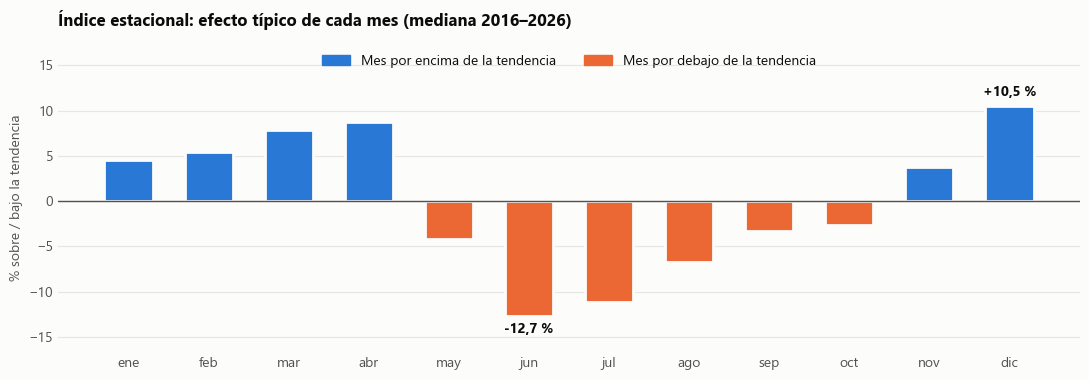

In [7]:
efecto = consistencia["efecto_pct"]
fig, ax = plt.subplots(figsize=(11, 3.9))
colores = [AZUL if v >= 0 else NARANJA for v in efecto]
ax.bar(MESES, efecto, width=0.6, color=colores, edgecolor=FONDO, linewidth=2)
ax.axhline(0, color=TINTA2, lw=1)
ax.yaxis.grid(True, color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left", "bottom"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
ax.set_ylabel("% sobre / bajo la tendencia")
for mes in ("dic", "jun"):                       # etiquetas selectivas: máximo y mínimo
    v = efecto[mes]
    ax.text(MESES.index(mes), v + (0.8 if v > 0 else -0.8), f"{v:+.1f} %".replace(".", ","), ha="center",
            va="bottom" if v > 0 else "top", color=TINTA, fontsize=10, fontweight="bold")
ax.set_ylim(efecto.min() - 4, efecto.max() + 7)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)],
          labels=["Mes por encima de la tendencia", "Mes por debajo de la tendencia"],
          loc="upper center", frameon=False, labelcolor=TINTA, ncol=2)
ax.set_title("Índice estacional: efecto típico de cada mes (mediana 2016–2026)",
             loc="left", fontsize=12, fontweight="bold", color=TINTA, pad=12)
fig.tight_layout()
fig.savefig("img/indice-estacional.svg", bbox_inches="tight")
plt.show()